# Construction d'une variable de qualité par clustering

**But : construire une classe à partir des propriétés mécaniques $Y$, puis apprendre plus tard à la prédire avec la composition et le procédé $X$.**

### Stratégie en cinq étapes

| Étape | Choix | Pourquoi |
|---|---|---|
| 1. Sélectionner | Quatre mesures disponibles, sans imputation | Construire les classes sur des mesures réelles |
| 2. Résumer | Standardisation → ACP → PC1 et PC2 | Mettre les unités à égalité et conserver environ 90 % de la variance |
| 3. Regrouper | K-means, de 2 à 8 groupes | Comparer séparation, stabilité et effectifs |
| 4. Interpréter | Médianes et distributions des quatre mesures | Donner un sens mécanique aux groupes |
| 5. Labelliser | Un label sur chaque cas complet | Préparer la future classification à partir de $X$ |

**Résultat de cette exploration :** deux profils se distinguent surtout par leur compromis résistance–ductilité. Leur ordre de qualité reste à définir selon l'usage.

### Données et paramètres

In [20]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("..") / "1. Données" / "02_intermediate" / "welddb_processed_vf.csv"
df = pd.read_csv(DATA_PATH, sep=";")

QUALITY_VARIABLES = [
    "Yield strength",
    "Ultimate tensile strength",
    "Elongation",
    "Reduction of Area",
]
ID_COL = "Weld ID"

print(f"Dataset : {df.shape[0]} lignes × {df.shape[1]} colonnes")

Dataset : 1652 lignes × 32 colonnes


## 1. Garder les soudures dont les quatre mesures sont connues

**Variables :** limite d'élasticité, résistance maximale, élongation et réduction de section.

**Choix :** utiliser les cas complets, sans imputation. Cela laisse **650 soudures sur 1 652**, issues de **82 Weld ID**. Cette population peut différer des lignes incomplètes.

In [21]:
complete_mask = df[QUALITY_VARIABLES].notna().all(axis=1)
quality_df = df.loc[complete_mask, [ID_COL] + QUALITY_VARIABLES].copy()

display(pd.DataFrame({
    "valeurs disponibles": df[QUALITY_VARIABLES].notna().sum(),
    "unité": ["MPa", "MPa", "%", "%"],
}))
print(
    f"Population retenue : {len(quality_df)} / {len(df)} soudures, "
    f"{quality_df[ID_COL].nunique()} Weld ID distincts."
)

,valeurs disponibles,unité
Yield strength,780,MPa
Ultimate tensile strength,738,MPa
Elongation,700,%
Reduction of Area,705,%


Population retenue : 650 / 1652 soudures, 82 Weld ID distincts.


## 2. Résumer les quatre mesures par deux axes d'ACP

**Choix :** centrer-réduire chaque variable, puis appliquer l'ACP. Les MPa et les pourcentages ont ainsi le même poids initial.

**Critère :** conserver au moins 90 % de la variance ; les deux premiers axes suffisent ici.

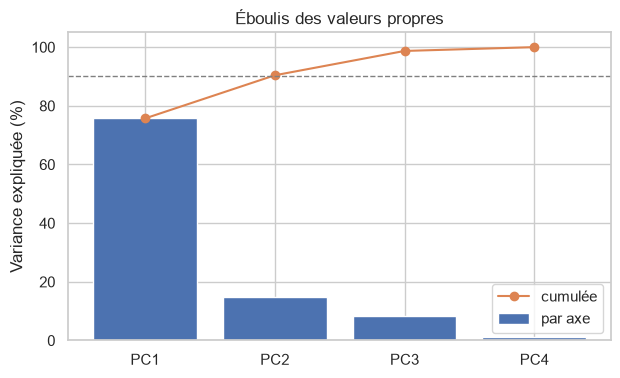

In [22]:
scaler_y = StandardScaler()
Y_scaled = scaler_y.fit_transform(quality_df[QUALITY_VARIABLES])

pca_y = PCA()
Y_scores_all = pca_y.fit_transform(Y_scaled)
component_names = [f"PC{i}" for i in range(1, len(QUALITY_VARIABLES) + 1)]
scores_df = pd.DataFrame(Y_scores_all, index=quality_df.index, columns=component_names)

pca_summary = pd.DataFrame({
    "variance expliquée (%)": 100 * pca_y.explained_variance_ratio_,
    "variance cumulée (%)": 100 * np.cumsum(pca_y.explained_variance_ratio_),
}, index=component_names)


fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(component_names, pca_summary["variance expliquée (%)"], label="par axe")
ax.plot(component_names, pca_summary["variance cumulée (%)"], "o-",
        color="C1", label="cumulée")
ax.axhline(90, color="grey", ls="--", lw=1)
ax.set(ylabel="Variance expliquée (%)", title="Éboulis des valeurs propres")
ax.legend()
plt.show()

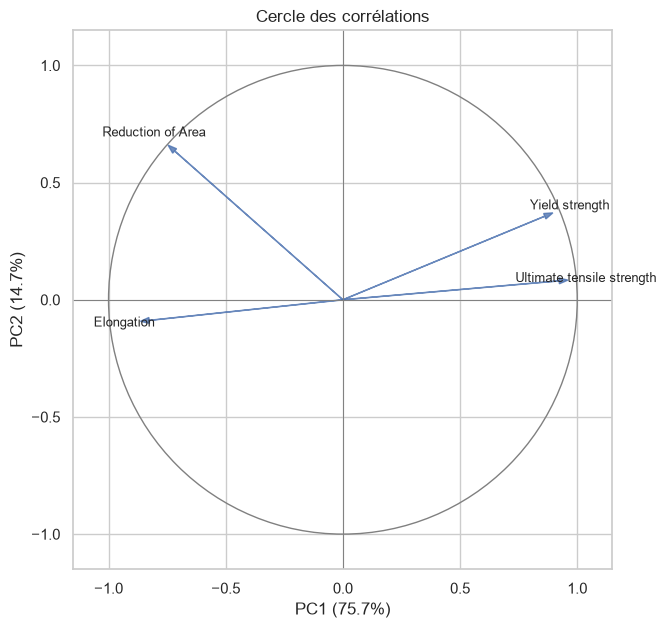

In [23]:
# Corrélations entre les variables standardisées et les composantes.
loadings = np.corrcoef(Y_scaled.T, Y_scores_all.T)[:4, 4:]
loadings_df = pd.DataFrame(loadings, index=QUALITY_VARIABLES, columns=component_names)


fig, ax = plt.subplots(figsize=(7, 7))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", lw=1))
for variable, row in loadings_df.iterrows():
    x, y = row["PC1"], row["PC2"]
    ax.arrow(0, 0, x, y, color="C0", alpha=.8, head_width=.025,
             length_includes_head=True)
    ax.text(1.08 * x, 1.08 * y, variable, ha="center", va="center", fontsize=9)
ax.axhline(0, color="grey", lw=.7)
ax.axvline(0, color="grey", lw=.7)
ax.set(
    xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal",
    xlabel=f"PC1 ({pca_y.explained_variance_ratio_[0]:.1%})",
    ylabel=f"PC2 ({pca_y.explained_variance_ratio_[1]:.1%})",
    title="Cercle des corrélations",
)
plt.show()

**À retenir : PC1 + PC2 expliquent 90,4 % de la variance.**

- **PC1 — 75,7 % :** oppose résistance élevée et ductilité élevée.
- **PC2 — 14,7 % :** apporte surtout une distinction liée à la réduction de section.

On utilise ces deux axes pour le clustering. Aucun axe ne mesure à lui seul une « bonne qualité ».

## 3. Choisir le nombre de groupes : séparation, stabilité, effectifs

**Méthode :** comparer K-means pour 2 à 8 groupes sur PC1–PC2.

| Diagnostic | Lecture |
|---|---|
| Silhouette | Plus elle est élevée, mieux les groupes sont séparés |
| Stabilité ARI | Proche de 1 : mêmes groupes entre initialisations |
| Effectif minimal | Repère les solutions créant de très petits groupes |

**Règle de choix :** privilégier une silhouette élevée, puis vérifier stabilité et effectifs. K-means produit toujours une partition ; ces critères ne prouvent pas l'existence de classes naturelles.

,silhouette,stabilité ARI,effectif minimal,effectif maximal
K,,,,
2,0.535,1.000,226,424
3,0.415,1.000,172,258
4,0.427,0.998,41,255
5,0.405,0.981,43,225
6,0.413,1.000,9,212
7,0.410,0.967,6,210
8,0.422,0.969,6,196


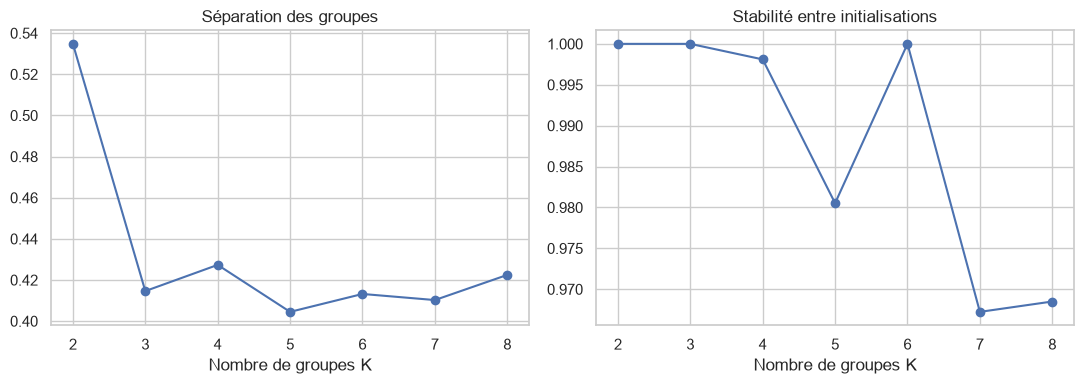

In [24]:
N_PCS_CLUSTERING = 2
K_CANDIDATES = range(2, 9)
Y_scores = Y_scores_all[:, :N_PCS_CLUSTERING]

diagnostics = []
models_by_k = {}
for k in K_CANDIDATES:
    model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(Y_scores)
    models_by_k[k] = model
    labels = model.labels_
    repeated_labels = [
        KMeans(n_clusters=k, n_init=30, random_state=seed).fit_predict(Y_scores)
        for seed in range(10)
    ]
    pairwise_ari = [
        adjusted_rand_score(a, b) for a, b in combinations(repeated_labels, 2)
    ]
    sizes = np.bincount(labels)
    diagnostics.append({
        "K": k,
        "silhouette": silhouette_score(Y_scores, labels),
        "stabilité ARI": np.mean(pairwise_ari),
        "effectif minimal": sizes.min(),
        "effectif maximal": sizes.max(),
    })

diagnostics_df = pd.DataFrame(diagnostics).set_index("K")
display(diagnostics_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
diagnostics_df["silhouette"].plot(marker="o", ax=axes[0], title="Séparation des groupes")
diagnostics_df["stabilité ARI"].plot(marker="o", ax=axes[1], title="Stabilité entre initialisations")
for ax in axes:
    ax.set_xlabel("Nombre de groupes K")
plt.tight_layout()
plt.show()

**Décision provisoire : retenir deux groupes.**

La silhouette atteint **environ 0,54**, contre **0,42–0,43** pour trois ou quatre groupes. Les deux effectifs sont **424 et 226**, et la partition est stable entre initialisations.

Il reste à vérifier ce que ces groupes représentent dans les mesures d'origine.

## 4. Interpréter les groupes avec les propriétés mécaniques

**Point clé : la séparation des deux groupes se fait principalement sur PC1 (75,7 % de la variance), l'axe qui traduit surtout le niveau de résistance mécanique.** Dans le plan ACP, la partition se lit donc d'abord horizontalement.

PC2 et les variables de ductilité apportent une différence secondaire, moins nette. Le tableau et les boîtes à moustaches permettent de vérifier cette lecture dans les unités d'origine et d'observer le recouvrement entre les groupes.

Le choix reste modifiable avec `N_CLUSTERS`. Les numéros des groupes sont de simples identifiants.

Médianes : résistances en MPa ; élongation et réduction de section en %.


,effectif,Weld ID distincts,Yield strength,Ultimate tensile strength,Elongation,Reduction of Area
quality_profile_cluster,,,,,,
0,424,57,456.2,541.0,29.2,77.4
1,226,47,573.0,679.5,22.0,66.8


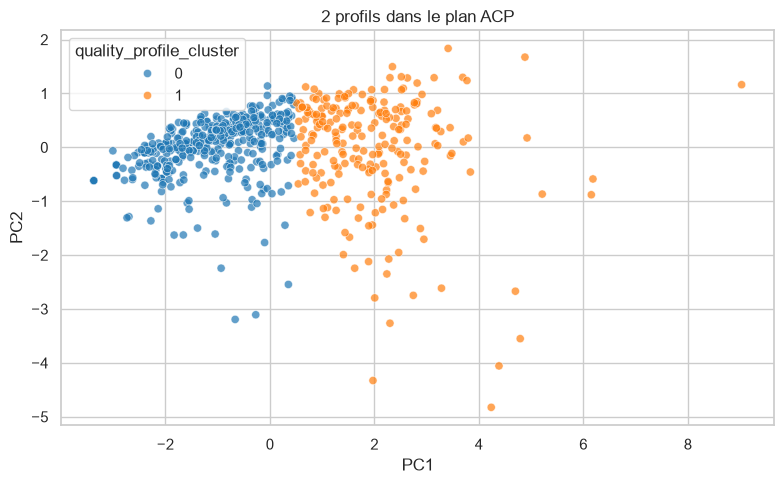

In [25]:
N_CLUSTERS = 2  # Hypothèse de travail, à discuter à partir des profils.

clusterer = models_by_k[N_CLUSTERS]
quality_df["quality_profile_cluster"] = clusterer.labels_
scores_df["quality_profile_cluster"] = clusterer.labels_

grouped = quality_df.groupby("quality_profile_cluster")
profiles = grouped[QUALITY_VARIABLES].median()
profiles.insert(0, "effectif", grouped.size())
profiles.insert(1, "Weld ID distincts", grouped[ID_COL].nunique())
print("Médianes : résistances en MPa ; élongation et réduction de section en %.")
display(profiles.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=scores_df, x="PC1", y="PC2", hue="quality_profile_cluster",
    palette="tab10", alpha=.7, s=35, ax=ax,
)
ax.set_title(f"{N_CLUSTERS} profils dans le plan ACP")
plt.tight_layout()
plt.show()

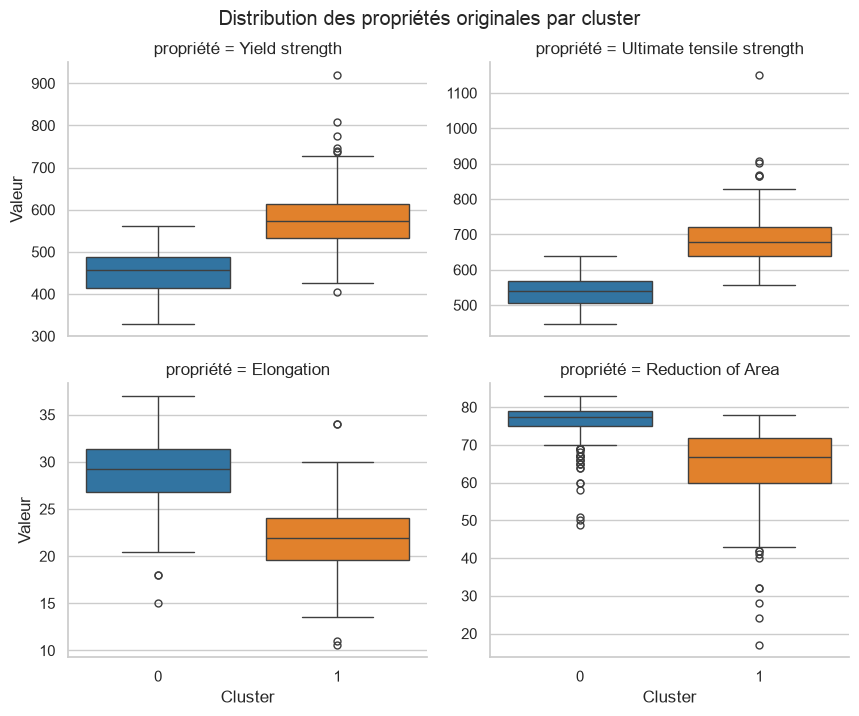

In [26]:
long_quality = quality_df.melt(
    id_vars=["quality_profile_cluster"], value_vars=QUALITY_VARIABLES,
    var_name="propriété", value_name="valeur",
)
g = sns.catplot(
    data=long_quality, x="quality_profile_cluster", y="valeur",
    col="propriété", col_wrap=2, kind="box", sharey=False,
    height=3.5, aspect=1.25, palette="tab10", hue="quality_profile_cluster",
    legend=False,
)
g.set_axis_labels("Cluster", "Valeur")
g.fig.suptitle("Distribution des propriétés originales par cluster", y=1.02)
plt.show()

**Lecture pour deux groupes : deux niveaux de résistance nettement séparés par PC1.**

| Profil | Effectif | Limite élastique | Résistance maximale | Élongation | Réduction de section |
|---|---:|---:|---:|---:|---:|
| Résistance modérée, ductilité élevée | 424 | 456 MPa | 541 MPa | 29,2 % | 77,4 % |
| Résistance élevée, ductilité plus faible | 226 | 573 MPa | 680 MPa | 22,0 % | 66,8 % |

*Valeurs médianes pour la configuration à deux groupes.*

**Interprétation :** la résistance est le critère réellement discriminant : le second groupe présente des limites élastique et maximale nettement plus élevées. Sa ductilité est aussi plus faible en moyenne, mais cette différence est secondaire et moins séparatrice. Ces profils ne constituent pas encore un classement « bonne / mauvaise qualité » : leur intérêt dépend des exigences de l'application, et une silhouette élevée ne suffit pas à prouver deux populations naturelles.

## 5. Créer le label sur les cas complets

**Sortie :** `quality_labels`, avec un identifiant de profil pour les 650 cas complets et une valeur manquante pour les autres lignes. Ce label est issu du clustering, pas d'une expertise indépendante.

La prédiction à partir de $X$ sera réalisée après validation de cette définition des classes.

In [27]:
quality_labels = df[[ID_COL]].copy()
quality_labels["quality_profile_cluster"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
quality_labels.loc[quality_df.index, "quality_profile_cluster"] = (
    quality_df["quality_profile_cluster"].astype("Int64")
)
quality_labels["quality_profile_observed"] = complete_mask

display(quality_labels.head())
print(quality_labels["quality_profile_cluster"].value_counts(dropna=False).sort_index())

assert quality_labels.loc[complete_mask, "quality_profile_cluster"].notna().all()
assert quality_labels.loc[~complete_mask, "quality_profile_cluster"].isna().all()
assert not quality_df[QUALITY_VARIABLES].isna().any().any()
print("Contrôles validés : labels observés uniquement sur les cas complets.")

,Weld ID,quality_profile_cluster,quality_profile_observed
0,Evans-Ni/CMn-1990,0,True
1,Evans-Ni/CMn-1990,<NA>,False
2,Evans-Ni/CMn-1990,0,True
3,Evans-Ni/CMn-1990,0,True
4,Evans-Ni/CMn-1990,<NA>,False


quality_profile_cluster
0        424
1        226
<NA>    1002
Name: count, dtype: Int64
Contrôles validés : labels observés uniquement sur les cas complets.


## Décision à discuter

**Proposition : conserver deux profils résistance–ductilité comme cible de classification.** Pour une qualité ordonnée (« faible / forte »), il faudra définir des exigences métier.

**Portée :** cette ACP et ce clustering sont exploratoires, ajustés sur tous les cas complets. Pour évaluer ensuite la prédiction sur de nouvelles soudures, il faudra séparer par `Weld ID`, ajuster standardisation, ACP et clustering sur le train, puis affecter les observations du test avec ces transformations figées. La même logique s'applique dans chaque fold de validation croisée.